# Ejercicio 5. Verificación de la detección de ciclos de Floyd

Este cuaderno acompaña al informe [`ejercicio-05.md`](ejercicio-05.md). Ejecuta el
mismo algoritmo, comprueba el invariante y los potenciales y genera
`ejercicio-05.png`. Las secciones siguen la numeración del informe.

La detección compara identidades de nodos después del avance. Las pruebas usan
valores repetidos y un oráculo independiente con nodos visitados. La memoria del
oráculo, las trazas y la construcción de las listas quedan fuera del costo del
algoritmo. Para reproducirlo hacen falta Python 3, `matplotlib` e `IPython`.


In [1]:
from itertools import product

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from IPython.display import Image, display


## 1. Formulación y modelo

Un nodo tiene un valor y un sucesor. `None` representa el final. El modelo cobra
costo constante por leer un enlace o comparar referencias y exige que los enlaces
no cambien durante la ejecución. Se cuentan solo los nodos alcanzables.

`make_chain(n, entry)` crea una cadena de $n$ nodos; si `entry` es un índice,
el último nodo apunta al de ese índice. Todos guardan el mismo valor para que
las pruebas distingan la identidad de la igualdad de valores.


In [2]:
class Node:
    __slots__ = ("value", "next")

    def __init__(self, value, next_node=None):
        self.value = value
        self.next = next_node


def make_chain(length, entry=None):
    assert length >= 0
    assert entry is None or 0 <= entry < length
    nodes = [Node(0) for _ in range(length)]
    for left, right in zip(nodes, nodes[1:]):
        left.next = right
    if nodes and entry is not None:
        nodes[-1].next = nodes[entry]
    return (nodes[0] if nodes else None), nodes


def inspect_list(head):
    # Oráculo: sigue UN enlace y recuerda identidades hasta None o una repetición.
    positions = {}
    ordered = []
    current = head
    while current is not None and current not in positions:
        positions[current] = len(ordered)
        ordered.append(current)
        current = current.next
    if current is None:
        return ordered, len(ordered), 0
    mu = positions[current]
    return ordered, mu, len(ordered) - mu


def position_at(shape, index):
    ordered, mu, period = shape
    if index < len(ordered):
        return ordered[index]
    if period == 0:
        return None
    return ordered[mu + (index - mu) % period]


assert inspect_list(None) == ([], 0, 0)
head, nodes = make_chain(7, 3)
assert inspect_list(head) == (nodes, 3, 4)
assert position_at(inspect_list(head), 8) is nodes[4]


## 2. Algoritmo

Esta función es idéntica a la del informe. No conoce $n$, $\mu$ ni $\lambda$,
no mantiene un contador de vueltas y no almacena nodos visitados.


In [3]:
def has_cycle(head):
    slow = fast = head
    while fast is not None and fast.next is not None:
        slow = slow.next
        fast = fast.next.next
        if slow is fast:
            return True
    return False


## 3. Invariante y correctitud parcial

La versión vigilada realiza los mismos avances y comprueba en cada vuelta
$\texttt{slow}=x_t$, $\texttt{fast}=x_{2t}$. Sus argumentos auxiliares y sus
aserciones pertenecen a las pruebas. Se incluyen el estado inicial y el último
estado, tanto si se sale por la guarda como si se encuentra un ciclo.


In [4]:
def first_meeting(mu, period):
    assert mu >= 0 and period >= 1
    return period * max(1, (mu + period - 1) // period)


def watched_floyd(head, shape):
    ordered, mu, period = shape
    n = len(ordered)
    bound = first_meeting(mu, period) if period else n // 2

    def potential(t):
        return bound - t if period else n - 2 * t

    slow = fast = head
    t = 0
    trace = [(t, slow, fast, potential(t))]
    assert slow is position_at(shape, 0)
    assert fast is position_at(shape, 0)
    assert potential(0) >= 0
    while fast is not None and fast.next is not None:
        assert t < bound, "se superó la cota demostrada de vueltas"
        assert slow is not None
        previous = potential(t)
        slow = slow.next
        fast = fast.next.next
        t += 1
        assert slow is position_at(shape, t)
        assert fast is position_at(shape, 2 * t)
        assert potential(t) >= 0
        assert previous - potential(t) == (1 if period else 2)
        trace.append((t, slow, fast, potential(t)))
        if slow is fast:
            assert period > 0
            assert t >= mu and t % period == 0
            assert t == bound and potential(t) == 0
            return True, trace
        if period and t >= mu:
            assert t % period != 0
    assert period == 0 and t == bound
    assert potential(t) in (0, 1)
    return False, trace


head, nodes = make_chain(7, 3)
example_shape = inspect_list(head)
example_result, example_trace = watched_floyd(head, example_shape)
assert has_cycle(head) is example_result is True
indices = {node: i for i, node in enumerate(nodes)}
example_rows = [(t, indices[slow], indices[fast], phi)
                for t, slow, fast, phi in example_trace]
assert example_rows == [
    (0, 0, 0, 4), (1, 1, 2, 3), (2, 2, 4, 2),
    (3, 3, 6, 1), (4, 4, 4, 0),
]
print('Tabla 1. Ejemplo con mu=3 y lambda=4')
print('t  lento  rápido  potencial')
for t, slow_index, fast_index, phi in example_rows:
    print(f'{t} {slow_index:6} {fast_index:7} {phi:10}')
print('La coincidencia inicial no se comprueba; el encuentro válido es en x_4.')


Tabla 1. Ejemplo con mu=3 y lambda=4
t  lento  rápido  potencial
0      0       0          4
1      1       2          3
2      2       4          2
3      3       6          1
4      4       4          0
La coincidencia inicial no se comprueba; el encuentro válido es en x_4.


## 4. Potenciales y terminación

En una cadena, $\Phi(t)=n-2t$ baja en 2 y la guarda es verdadera si y solo si
$\Phi\ge2$. Con ciclo, el primer encuentro válido corresponde al menor múltiplo
positivo de $\lambda$ no menor que $\mu$:

$$T=\lambda\max\{1,\lceil\mu/\lambda\rceil\},\qquad\Psi(t)=T-t.$$

`watched_floyd` comprueba que el potencial es entero no negativo, desciende en
cada vuelta y produce el número exacto de vueltas. Se comparan sus resultados
con `has_cycle` y con el oráculo independiente. También se verifica que ningún
enlace cambia. Se prueban 129 cadenas y 4160 listas con ciclo.


In [5]:
acyclic_records = []
cyclic_records = []


def verify_case(head, nodes):
    before = [node.next for node in nodes]
    shape = inspect_list(head)
    ordered, mu, period = shape
    expected = period > 0
    assert has_cycle(head) is expected
    result, trace = watched_floyd(head, shape)
    assert result is expected
    assert all(node.next is link for node, link in zip(nodes, before))
    return shape, trace


for n in range(129):
    head, nodes = make_chain(n)
    shape, trace = verify_case(head, nodes)
    assert shape == (nodes, n, 0)
    rounds = len(trace) - 1
    assert rounds == n // 2
    assert trace[-1][3] == n % 2
    acyclic_records.append((n, rounds))

for mu in range(65):
    for period in range(1, 65):
        head, nodes = make_chain(mu + period, mu)
        shape, trace = verify_case(head, nodes)
        assert shape == (nodes, mu, period)
        rounds = len(trace) - 1
        assert rounds == first_meeting(mu, period)
        # Oráculo aritmético sin usar la fórmula de first_meeting.
        first_multiple = next(t for t in range(1, mu + period + 1)
                              if t >= mu and t % period == 0)
        assert rounds == first_multiple
        assert max(mu, period) <= rounds <= mu + period
        assert 2 * rounds >= mu + period
        assert trace[-1][3] == 0
        cyclic_records.append((mu, period, rounds))

assert len(acyclic_records) == 129
assert len(cyclic_records) == 4160
print(f'ok: {len(acyclic_records)} cadenas sin ciclo, de 0 a 128 nodos')
print(f'ok: {len(cyclic_records)} pares (mu, lambda), incluidos ciclos desde la cabeza y autociclos')
print('ok: invariante, descenso de potenciales, vueltas exactas y enlaces conservados')


ok: 129 cadenas sin ciclo, de 0 a 128 nodos
ok: 4160 pares (mu, lambda), incluidos ciclos desde la cabeza y autociclos
ok: invariante, descenso de potenciales, vueltas exactas y enlaces conservados


## 5. Costo y verificación exhaustiva de casos pequeños

El número de vueltas es $\lfloor n/2\rfloor$ sin ciclo y está entre $n/2$ y $n$
con ciclo. Cada vuelta cuesta $\Theta(1)$; el tiempo es $\Theta(n+1)$ y la memoria
auxiliar es $\Theta(1)$. La instrumentación anterior se excluye de ese costo.

Para cubrir también nodos inaccesibles y distintas cabezas, se enumeran todos
los grafos de sucesor sobre $k=0,\ldots,5$ nodos. Cada nodo tiene $k+1$ sucesores
posibles, incluido `None`, y se prueban las $k+1$ cabezas posibles:

$$\sum_{k=0}^5 (k+1)^{k+1}=50\,069.$$

En cada caso se ejecuta directamente `has_cycle`, se compara con el recorrido
con visitados y se comprueba la conservación de todos los enlaces. Los ciclos
inaccesibles desde la cabeza deben ignorarse.


In [6]:
exhaustive_cases = 0
positive_cases = 0
negative_cases = 0
cases_by_size = []
for size in range(6):
    nodes = [Node(0) for _ in range(size)]
    count = 0
    for successors in product(range(-1, size), repeat=size):
        for node, successor in zip(nodes, successors):
            node.next = None if successor == -1 else nodes[successor]
        before = [node.next for node in nodes]
        for head in [None] + nodes:
            _, _, period = inspect_list(head)
            result = has_cycle(head)
            assert result is (period > 0)
            assert all(node.next is link for node, link in zip(nodes, before))
            exhaustive_cases += 1
            count += 1
            positive_cases += int(result)
            negative_cases += int(not result)
    assert count == (size + 1) ** (size + 1)
    cases_by_size.append(count)

assert cases_by_size == [1, 4, 27, 256, 3125, 46656]
assert exhaustive_cases == 50069
assert positive_cases + negative_cases == exhaustive_cases
print(f'ok: {exhaustive_cases} casos exhaustivos sobre 0 a 5 nodos')
print(f'Con ciclo alcanzable: {positive_cases}; sin ciclo alcanzable: {negative_cases}')
print('ok: resultados iguales al oráculo y ningún enlace modificado')

# Un ciclo que existe en la estructura pero es inaccesible desde la cabeza.
head, nodes = make_chain(3)
nodes[1].next = nodes[1]
nodes[0].next = nodes[2]
assert has_cycle(head) is False
assert has_cycle(nodes[1]) is True
print('ok: un ciclo inaccesible se ignora desde la cabeza')


ok: 50069 casos exhaustivos sobre 0 a 5 nodos
Con ciclo alcanzable: 26761; sin ciclo alcanzable: 23308
ok: resultados iguales al oráculo y ningún enlace modificado
ok: un ciclo inaccesible se ignora desde la cabeza


## Figura 1

A la izquierda se dibuja el ejemplo $\mu=3$, $\lambda=4$. Se resalta $x_4$,
donde se encuentran los punteros tras cuatro vueltas. A la derecha se muestra
el descenso de sus potenciales y el de una cadena sin ciclo de nueve nodos.
En esta última, la guarda es falsa al quedar $\Phi=1$. El potencial no tiene
que terminar en cero para demostrar terminación.


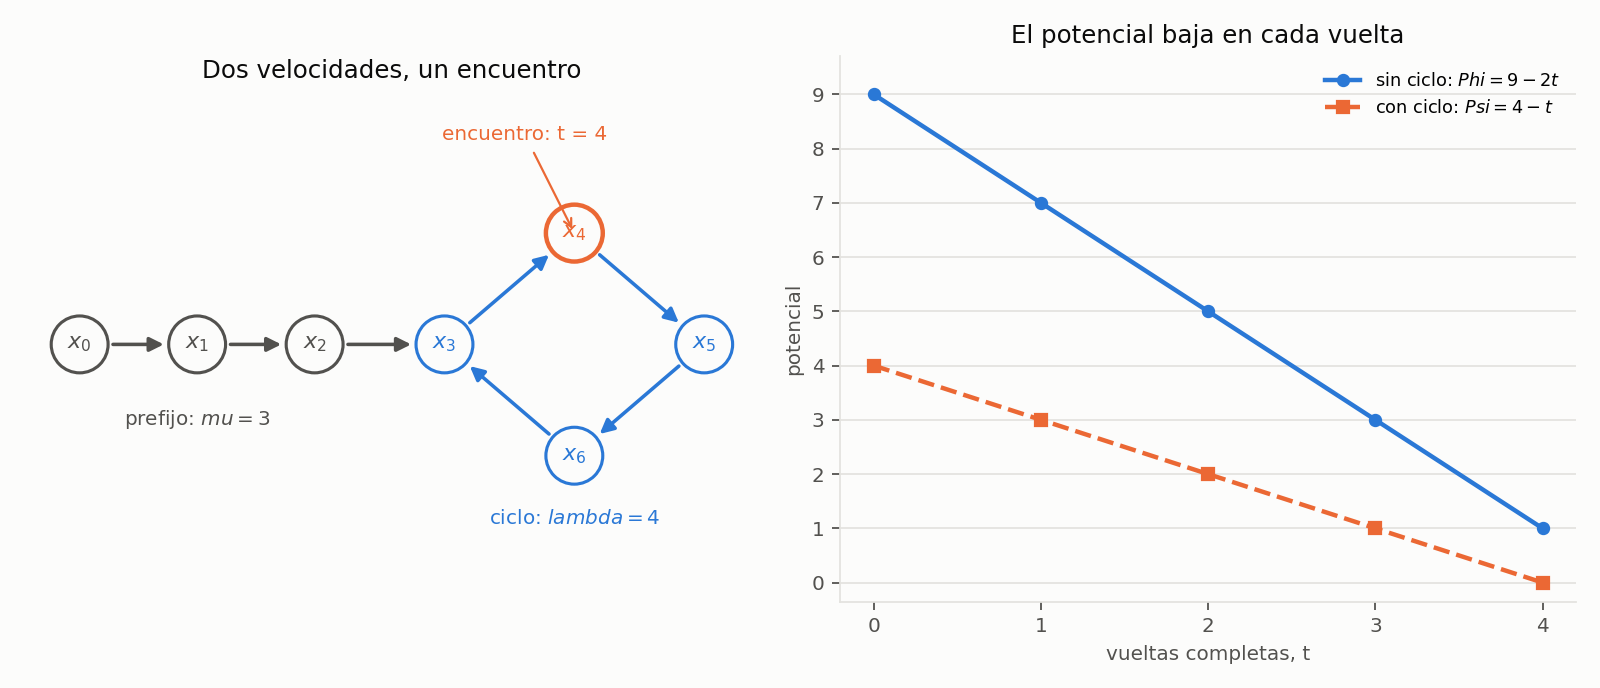

In [7]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary_ink = '#0b0b0b', '#52514e'
grid_color, background = '#e4e3df', '#fcfcfb'
fig, (ax_list, ax_phi) = plt.subplots(1, 2, figsize=(10, 4.3), dpi=160)
fig.patch.set_facecolor(background)

positions = {
    0: (0, 0), 1: (0.95, 0), 2: (1.9, 0),
    3: (2.95, 0), 4: (4, 0.9), 5: (5.05, 0), 6: (4, -0.9),
}
for i, j in [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 3)]:
    start, end = positions[i], positions[j]
    color = blue if i >= 3 else secondary_ink
    ax_list.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>',
                                     mutation_scale=13, lw=1.6, color=color,
                                     shrinkA=15, shrinkB=15))
for i, (x, y) in positions.items():
    color = orange if i == 4 else blue if i >= 3 else secondary_ink
    ax_list.add_patch(Circle((x, y), 0.23, facecolor=background,
                            edgecolor=color, lw=2 if i == 4 else 1.4, zorder=3))
    ax_list.text(x, y, rf'$x_{i}$', ha='center', va='center', fontsize=10,
                 color=color, zorder=4)
ax_list.text(0.95, -0.65, r'prefijo: $mu=3$', ha='center',
             color=secondary_ink, fontsize=9)
ax_list.text(4, -1.45, r'ciclo: $lambda=4$', ha='center', color=blue, fontsize=9)
ax_list.annotate('encuentro: t = 4', xy=positions[4], xytext=(3.6, 1.65),
                  ha='center', fontsize=9, color=orange,
                  arrowprops=dict(arrowstyle='->', color=orange, lw=1))
ax_list.set_xlim(-0.45, 5.5)
ax_list.set_ylim(-1.8, 2.05)
ax_list.set_aspect('equal')
ax_list.axis('off')
ax_list.set_title('Dos velocidades, un encuentro', color=ink, fontsize=11)

acyclic_head, _ = make_chain(9)
_, acyclic_trace = watched_floyd(acyclic_head, inspect_list(acyclic_head))
ax_phi.plot([r[0] for r in acyclic_trace], [r[3] for r in acyclic_trace],
            'o-', color=blue, lw=2, ms=5, label=r'sin ciclo: $Phi=9-2t$')
ax_phi.plot([r[0] for r in example_trace], [r[3] for r in example_trace],
            's--', color=orange, lw=2, ms=5, label=r'con ciclo: $Psi=4-t$')
ax_phi.set_title('El potencial baja en cada vuelta', color=ink, fontsize=11)
ax_phi.set_xlabel('vueltas completas, t', color=secondary_ink, fontsize=9)
ax_phi.set_ylabel('potencial', color=secondary_ink, fontsize=9)
ax_phi.set_xticks(range(5))
ax_phi.set_yticks(range(10))
ax_phi.set_ylim(-0.35, 9.7)
ax_phi.set_facecolor(background)
ax_phi.grid(axis='y', color=grid_color, lw=0.8)
for side in ['top', 'right']:
    ax_phi.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax_phi.spines[side].set_color(grid_color)
ax_phi.tick_params(colors=secondary_ink, labelsize=9)
ax_phi.legend(frameon=False, fontsize=8, loc='upper right')
fig.tight_layout()
fig.savefig('ejercicio-05.png', facecolor=background)
plt.close(fig)
display(Image(filename='ejercicio-05.png'))


## 6. Conclusiones

Las posiciones $x_t$ y $x_{2t}$ dan el invariante. La condición de encuentro en
un ciclo es $t\ge\mu$ y $\lambda\mid t$, con $t>0$. El potencial $n-2t$
demuestra la terminación sin ciclo, y $T-t$ la demuestra con ciclo. El resultado
es exacto, el tiempo es $\Theta(n+1)$ y la memoria auxiliar es $\Theta(1)$.

Las pruebas verifican las implementaciones y los tamaños enumerados; las
demostraciones del informe cubren todas las listas del modelo.


In [8]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Cadenas sin ciclo: {len(acyclic_records)}')
print(f'Listas con ciclo: {len(cyclic_records)}')
print(f'Casos exhaustivos de grafos de sucesor: {exhaustive_cases}')
print('Figura guardada en ejercicio-05.png')


Todas las comprobaciones finalizaron correctamente.
Cadenas sin ciclo: 129
Listas con ciclo: 4160
Casos exhaustivos de grafos de sucesor: 50069
Figura guardada en ejercicio-05.png
